# Dependencia de la red vial para llegar al hospital

El ejercicio parte de las localidades de Yécora y los establecimientos hospitalarios del catálogo CLUES dentro de un recorte regional. Mide qué tramos comparten sus rutas y el efecto de retirar un tramo del grafo.

El tiempo calculado usa la longitud y velocidad de cada tramo de la Red Nacional de Caminos 2025. Los puntos se ajustan a nodos de la red y el tiempo comienza en el nodo. El modelo conserva los sentidos de circulación. Las maniobras prohibidas y las condiciones de viaje quedan fuera del cálculo. El recorte puede dejar fuera rutas alternativas y establecimientos. Los resultados describen un escenario de la red modelada.

[Preparación de la RNC](../docs/workflow.md) · [Diccionario de accesibilidad](../references/diccionario_accesibilidad_localidades.md)

In [1]:
from pathlib import Path
from shutil import copyfileobj
from zipfile import ZipFile

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra
from scipy.spatial import cKDTree

get_ipython().run_line_magic("matplotlib", "inline")

inicio = Path.cwd().resolve()
raiz = next(ruta for ruta in (inicio, *inicio.parents) if (ruta / "config/fuentes_health.yaml").is_file())
ruta_zip = raiz / "data/raw/Red_Nacional_de_Caminos_2025.zip"
ruta_red = raiz / "data/interim/rnc2025.gpkg"
miembro = "conjunto_de_datos/rnc2025.gpkg"
ruta_red.parent.mkdir(parents=True, exist_ok=True)
with ZipFile(ruta_zip) as archivo:
    bytes_esperados = archivo.getinfo(miembro).file_size
    vigente = (ruta_red.is_file() and ruta_red.stat().st_size == bytes_esperados
               and ruta_red.stat().st_mtime >= ruta_zip.stat().st_mtime)
    if not vigente:
        temporal = ruta_red.with_suffix(".gpkg.part")
        with archivo.open(miembro) as origen, temporal.open("wb") as destino:
            copyfileobj(origen, destino, 8 * 1024**2)
        temporal.replace(ruta_red)

# Longitud oeste, latitud sur, longitud este, latitud norte en EPSG:6365.
recorte = (-111.8, 26.95, -107.75, 30.35)
municipio_piloto = "YECORA"
max_ajuste_m = 5_000
campos = ["ID_RED", "TIPO_VIAL", "NOMBRE", "CODIGO", "ESTATUS", "CIRCULA",
          "VELOCIDAD", "UNION_INI", "UNION_FIN", "LONGITUD"]
red = gpd.read_file(ruta_red, layer="red_vial", bbox=recorte, columns=campos)
nodos = gpd.read_file(ruta_red, layer="union_p", bbox=recorte, columns=["ID_UNION"])
nodos = nodos.dropna(subset=["ID_UNION", "geometry"]).drop_duplicates("ID_UNION").reset_index(drop=True)
nodos["nodo"] = np.arange(len(nodos), dtype=int)
indices = nodos.set_index("ID_UNION")["nodo"]
red["origen"] = red["UNION_INI"].map(indices)
red["destino"] = red["UNION_FIN"].map(indices)
velocidad = pd.to_numeric(red["VELOCIDAD"], errors="coerce")
metros = pd.to_numeric(red["LONGITUD"], errors="coerce")
usable = (
    red["ESTATUS"].eq("Habilitado") & red["CIRCULA"].isin(["Un sentido", "Dos sentidos"])
    & velocidad.gt(0) & metros.gt(0) & red[["origen", "destino", "ID_RED"]].notna().all(axis=1)
    & red["origen"].ne(red["destino"])
)
tramos = red.loc[usable].copy()
tramos[["origen", "destino"]] = tramos[["origen", "destino"]].astype(int)
tramos["minutos"] = (metros.loc[usable] / 1000 / velocidad.loc[usable] * 60)
assert not tramos.empty and tramos["ID_RED"].is_unique
display(pd.Series({
    "Tramos en el recorte": len(red),
    "Tramos incorporados al grafo": len(tramos),
    "Nodos leídos": len(nodos),
}, name="valor").to_frame())

,valor
Tramos en el recorte,101415
Tramos incorporados al grafo,97378
Nodos leídos,81359


## Puntos de partida y destinos

Se ajusta cada localidad y hospital al nodo activo más cercano. La distancia máxima de ajuste es de 5 km. El modelo toma como destino el hospital que minimiza el tiempo entre nodos, incluido el cambio de hospital cuando se simula el cierre.

In [2]:
procesados = raiz / "data/processed"
acceso = pd.read_parquet(procesados / "accesibilidad_localidades.parquet")
salud = pd.read_parquet(procesados / "salud-001_establecimientos.parquet")
nombre_normalizado = (acceso["municipality_name"].str.normalize("NFKD")
                      .str.encode("ascii", errors="ignore").str.decode("ascii").str.upper())
localidades = acceso.loc[nombre_normalizado.eq(municipio_piloto), [
    "locality_id", "locality_name", "population", "longitude", "latitude"
]].copy()
hospitales = salud.loc[
    salud["nivel_atencion"].str.contains("SEGUNDO|TERCER", na=False)
    | salud["tipo_establecimiento"].str.contains("HOSPITALIZACION", na=False)
].copy()
hospitales = hospitales.rename(columns={"longitud": "longitude", "latitud": "latitude"})
hospitales["longitude"] = pd.to_numeric(hospitales["longitude"], errors="coerce")
hospitales["latitude"] = pd.to_numeric(hospitales["latitude"], errors="coerce")
x_min, y_min, x_max, y_max = recorte
hospitales = hospitales.loc[
    hospitales["longitude"].between(x_min, x_max) & hospitales["latitude"].between(y_min, y_max)
].copy()

nodos_activos = np.unique(tramos[["origen", "destino"]].to_numpy())
proyeccion = "EPSG:32612"
geometrias = nodos.geometry.iloc[nodos_activos].to_crs(proyeccion)
arbol = cKDTree(np.column_stack([geometrias.x, geometrias.y]))

def ajustar_a_nodo(tabla):
    puntos = gpd.GeoSeries(gpd.points_from_xy(tabla["longitude"], tabla["latitude"]),
                           crs="EPSG:4326").to_crs(proyeccion)
    ajuste, posicion = arbol.query(np.column_stack([puntos.x, puntos.y]))
    return tabla.assign(nodo=nodos_activos[posicion], ajuste_m=ajuste)

localidades = ajustar_a_nodo(localidades.dropna(subset=["longitude", "latitude"]))
hospitales = ajustar_a_nodo(hospitales)
simuladas = localidades.loc[localidades["ajuste_m"].le(max_ajuste_m)].copy()
destinos = (hospitales.loc[hospitales["ajuste_m"].le(max_ajuste_m)]
            .sort_values("clues").drop_duplicates("nodo").set_index("nodo"))
if simuladas.empty or destinos.empty:
    raise ValueError("El recorte y la distancia de ajuste deben incluir localidades y hospitales.")
display(pd.Series({
    "Localidades del municipio con coordenadas": len(localidades),
    "Localidades ajustadas al grafo": len(simuladas),
    "Personas en las localidades ajustadas": int(simuladas["population"].sum()),
    "Hospitales con coordenadas en el recorte": len(hospitales),
    "Nodos con hospital ajustado": len(destinos),
}, name="valor").to_frame())

,valor
Localidades del municipio con coordenadas,70
Localidades ajustadas al grafo,70
Personas en las localidades ajustadas,4793
Hospitales con coordenadas en el recorte,60
Nodos con hospital ajustado,55


## Rutas base y cierre simulado

El tramo del escenario se elige entre las carreteras que aparecen en rutas base. Se prioriza la carretera que concentra la mayor población asignada a esas rutas. El escenario retira ambos sentidos del tramo y vuelve a calcular el hospital alcanzable de menor tiempo.

In [3]:
def calcular_rutas(tramos_disponibles):
    arcos = tramos_disponibles[["ID_RED", "origen", "destino", "minutos"]]
    retorno = arcos.loc[tramos_disponibles["CIRCULA"].eq("Dos sentidos")].rename(
        columns={"origen": "destino", "destino": "origen"}
    )
    arcos = (pd.concat([arcos, retorno]).sort_values(["minutos", "ID_RED"])
             .drop_duplicates(["origen", "destino"]))
    grafo_inverso = csr_matrix(
        (arcos["minutos"], (arcos["destino"], arcos["origen"])),
        shape=(len(nodos), len(nodos)),
    )
    tiempos, siguientes, hospitales_finales = dijkstra(
        grafo_inverso, indices=destinos.index.to_numpy(), min_only=True, return_predecessors=True
    )
    ids = arcos.set_index(["origen", "destino"])["ID_RED"].to_dict()
    return tiempos, siguientes, hospitales_finales, ids

def tramos_de_ruta(nodo, siguientes, ids):
    tramo_ids = []
    while siguientes[nodo] != -9999:
        siguiente = int(siguientes[nodo])
        tramo_ids.append(ids[(nodo, siguiente)])
        nodo = siguiente
    return tramo_ids

antes, siguientes_antes, hospitales_antes, ids_antes = calcular_rutas(tramos)
simuladas["antes_min"] = antes[simuladas["nodo"]]
base = simuladas.loc[np.isfinite(simuladas["antes_min"])].copy()
uso = []
for fila in base.itertuples():
    for id_tramo in dict.fromkeys(tramos_de_ruta(fila.nodo, siguientes_antes, ids_antes)):
        uso.append((id_tramo, fila.population))
if not uso:
    raise ValueError("No hay trayectos con tramos de red en el escenario base.")
dependencia = (pd.DataFrame(uso, columns=["ID_RED", "personas"]).groupby("ID_RED")
               .agg(personas=("personas", "sum"), rutas=("personas", "size"))
               .join(tramos.set_index("ID_RED")[["TIPO_VIAL", "NOMBRE", "CODIGO"]])
               .sort_values(["personas", "rutas"], ascending=False))
carreteras = dependencia[dependencia["TIPO_VIAL"].str.upper().eq("CARRETERA")]
if carreteras.empty:
    raise ValueError("Las rutas base no incluyen tramos de tipo Carretera.")
id_cierre = carreteras.index[0]
display(carreteras.head(10))

despues, siguientes_despues, hospitales_despues, ids_despues = calcular_rutas(
    tramos.loc[tramos["ID_RED"].ne(id_cierre)]
)
base["despues_min"] = despues[base["nodo"]]
base["con_ruta"] = np.isfinite(base["despues_min"])
base["aumento_min"] = (base["despues_min"] - base["antes_min"]).where(base["con_ruta"])
base["hospital_antes"] = destinos["clues"].reindex(hospitales_antes[base["nodo"]]).to_numpy()
base["hospital_despues"] = destinos["clues"].reindex(hospitales_despues[base["nodo"]]).to_numpy()
base["cambia_hospital"] = base["con_ruta"] & base["hospital_antes"].ne(base["hospital_despues"])
assert base["aumento_min"].dropna().ge(-1e-6).all()
base["aumento_min"] = base["aumento_min"].clip(lower=0)
demora = base["aumento_min"].gt(1e-6)
sin_ruta = ~base["con_ruta"]
impacto = pd.Series({
    "ID del tramo cerrado": int(id_cierre),
    "Localidades con ruta base": len(base),
    "Localidades con aumento de tiempo": int(demora.sum()),
    "Personas en localidades con aumento de tiempo": int(base.loc[demora, "population"].sum()),
    "Localidades sin ruta tras el cierre": int(sin_ruta.sum()),
    "Personas en localidades sin ruta tras el cierre": int(base.loc[sin_ruta, "population"].sum()),
    "Localidades que cambian de hospital": int(base["cambia_hospital"].sum()),
    "Máximo aumento con ruta (min)": base.loc[base["con_ruta"], "aumento_min"].max(),
}, name="valor")
display(impacto.to_frame().round(2))

,personas,rutas,TIPO_VIAL,NOMBRE,CODIGO
ID_RED,,,,,
457539,4558,65,Carretera,Esperanza - Presa Álvaro Obregón,117
457568,4558,65,Carretera,Esperanza - Presa Álvaro Obregón,117
457595,4558,65,Carretera,Esperanza - Presa Álvaro Obregón,117
457626,4558,65,Carretera,Esperanza - Hornos - San Nicolás,117
457766,4558,65,Carretera,Esperanza - Presa Álvaro Obregón,117
457781,4558,65,Carretera,Ciudad Obregón - Hermosillo,15
457786,4558,65,Carretera,Esperanza - Presa Álvaro Obregón,117
457826,4558,65,Carretera,Esperanza - Presa Álvaro Obregón,117
457884,4558,65,Carretera,Ciudad Obregón - Hermosillo,15


,valor
ID del tramo cerrado,457539.00
Localidades con ruta base,70.00
Localidades con aumento de tiempo,65.00
Personas en localidades con aumento de tiempo,4558.00
Localidades sin ruta tras el cierre,0.00
Personas en localidades sin ruta tras el cierre,0.00
Localidades que cambian de hospital,0.00
Máximo aumento con ruta (min),5.23


## Impacto por localidad

La tabla muestra primero las localidades que pierden su ruta al hospital y después las que conservan una ruta con mayor tiempo. El mapa muestra la ruta base y, cuando existe, el desvío de la localidad afectada con mayor población.

,locality_name,population,antes_min,despues_min,aumento_min,hospital_antes,hospital_despues
6952,Yécora,2453,181.2,186.4,5.2,SRSMP002052,SRSMP002052
6959,Maycoba,658,215.1,220.4,5.2,SRSMP002052,SRSMP002052
6971,Tepoca,255,147.0,152.2,5.2,SRSMP002052,SRSMP002052
6957,Guadalupe de Tayopa,161,163.6,168.8,5.2,SRSMP002052,SRSMP002052
6964,La Quema,131,139.8,145.0,5.2,SRSMP002052,SRSMP002052
6965,El Kipur,130,220.6,225.8,5.2,SRSMP002052,SRSMP002052
7012,Pimas (Juan Diego de los Pimas),128,181.1,186.4,5.2,SRSMP002052,SRSMP002052
6969,Santa Ana,92,166.6,171.8,5.2,SRSMP002052,SRSMP002052
6955,La Concepción,64,149.5,154.7,5.2,SRSMP002052,SRSMP002052
6989,El Encinal,55,218.5,223.7,5.2,SRSMP002052,SRSMP002052


El cierre del tramo **457539** produce un aumento del tiempo en **65** localidades y deja **0** sin ruta dentro del recorte modelado.

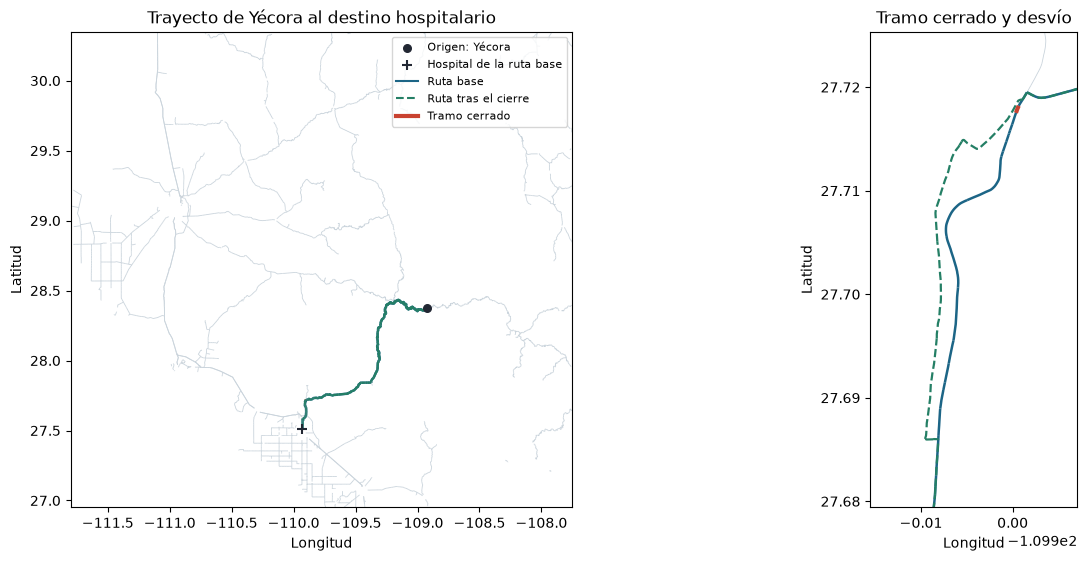

In [4]:
afectadas = base.loc[demora | sin_ruta].sort_values(
    ["con_ruta", "population"], ascending=[True, False]
)
display(afectadas[["locality_name", "population", "antes_min", "despues_min", "aumento_min",
                   "hospital_antes", "hospital_despues"]].replace(np.inf, pd.NA).head(15).round(1))
display(Markdown(
    f"El cierre del tramo **{id_cierre}** produce un aumento del tiempo en **{int(demora.sum())}** "
    f"localidades y deja **{int(sin_ruta.sum())}** sin ruta dentro del recorte modelado."
))

figura, (eje, detalle) = plt.subplots(1, 2, figsize=(13, 5.5), layout="constrained")
tramos_geo = tramos.set_index("ID_RED")
fondo = tramos_geo.loc[tramos_geo["TIPO_VIAL"].str.upper().eq("CARRETERA")]
recorrido, alterna = [], []
if not afectadas.empty:
    ejemplo = afectadas.sort_values("population", ascending=False).iloc[0]
    recorrido = tramos_de_ruta(ejemplo["nodo"], siguientes_antes, ids_antes)
    if ejemplo["con_ruta"]:
        alterna = tramos_de_ruta(ejemplo["nodo"], siguientes_despues, ids_despues)
    eje.scatter(ejemplo["longitude"], ejemplo["latitude"], color="#222733",
                s=30, zorder=6, label=f"Origen: {ejemplo['locality_name']}")
    hospital = destinos.loc[destinos["clues"].eq(ejemplo["hospital_antes"])].iloc[0]
    eje.scatter(hospital["longitude"], hospital["latitude"], color="#222733", marker="+",
                s=50, zorder=6, label="Hospital de la ruta base")

for mapa in (eje, detalle):
    fondo.plot(ax=mapa, color="#cad4dc", linewidth=.6)
    if recorrido:
        tramos_geo.loc[recorrido].plot(ax=mapa, color="#1c6586", linewidth=1.8)
        mapa.plot([], [], color="#1c6586", label="Ruta base")
    if alterna:
        tramos_geo.loc[alterna].plot(ax=mapa, color="#247f65", linewidth=1.6, linestyle="--")
        mapa.plot([], [], color="#247f65", linestyle="--", label="Ruta tras el cierre")
    tramos_geo.loc[[id_cierre]].plot(ax=mapa, color="#c94230", linewidth=3, zorder=5)
    mapa.plot([], [], color="#c94230", linewidth=3, label="Tramo cerrado")
    mapa.set(xlabel="Longitud", ylabel="Latitud")

ids_detalle = {id_cierre}
if alterna:
    ids_detalle.update(set(recorrido).symmetric_difference(alterna))
oeste, sur, este, norte = tramos_geo.loc[sorted(ids_detalle)].total_bounds
margen_lon = max((este - oeste) * .2, .006)
margen_lat = max((norte - sur) * .2, .006)
eje.set(title="Trayecto de Yécora al destino hospitalario", xlim=(x_min, x_max), ylim=(y_min, y_max))
detalle.set(title="Tramo cerrado y desvío",
            xlim=(oeste - margen_lon, este + margen_lon), ylim=(sur - margen_lat, norte + margen_lat))
eje.legend(loc="upper right", fontsize=8)
plt.show()

In [5]:
base.assign(
    municipio=municipio_piloto,
    tramo_cerrado=int(id_cierre),
    despues_min=base["despues_min"].where(base["con_ruta"]),
)[["municipio", "tramo_cerrado", "locality_id", "locality_name", "population", "antes_min",
   "despues_min", "aumento_min", "con_ruta", "hospital_antes", "hospital_despues"]].to_parquet(
    procesados / "escenario_vial_localidades.parquet", index=False
)

capas = []
for etiqueta, ids_tramos in (("Ruta base", recorrido), ("Ruta tras el cierre", alterna), ("Tramo cerrado", [id_cierre])):
    if ids_tramos:
        capas.append(tramos_geo.loc[list(dict.fromkeys(ids_tramos)), ["geometry"]].assign(trayecto=etiqueta))
geometrias_tablero = gpd.GeoDataFrame(pd.concat(capas, ignore_index=True), crs=tramos_geo.crs)
(procesados / "escenario_vial_trayectos.geojson").write_text(
    geometrias_tablero.to_json(to_wgs84=True, drop_id=True), encoding="utf-8"
)

812720